Investigate our data_raw

In [338]:
#Import libraries
import numpy as np
import matplotlib.pyplot as plt
import solarpy
import pvlib
import pandas as pd
from matplotlib.colors import Normalize

#Plot settings
plt.rcParams.update({
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14,
})

STATION = "06019"
LATITUDE = 56.93
LONGITUDE = 8.6412

In [339]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from scripts.functions import get_dmi_ghi, resample_dmi_ghi_hourly

In [340]:
data_raw = get_dmi_ghi(
    start="2025-11-09",
    end="2026-11-09",
    station="06019",
)

data_raw.head(20)

parameterId,ghi
timestamp,
2025-11-09 00:00:00+00:00,0.0
2025-11-09 00:10:00+00:00,0.0
2025-11-09 00:20:00+00:00,0.0
2025-11-09 00:30:00+00:00,0.0
2025-11-09 00:40:00+00:00,0.0
2025-11-09 00:50:00+00:00,0.0
2025-11-09 01:00:00+00:00,0.0
2025-11-09 01:10:00+00:00,0.0
2025-11-09 01:20:00+00:00,0.0


In [341]:
data_raw.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 52498 entries, 2025-11-09 00:00:00+00:00 to 2026-11-09 00:00:00+00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ghi     52498 non-null  float64
dtypes: float64(1)
memory usage: 820.3 KB


In [342]:
data_raw.describe()

parameterId,ghi
count,52498.000000
mean,122.589622
std,213.730409
min,0.000000
25%,0.000000
50%,2.000000
75%,151.750000
max,1168.000000


#### Solar position for BRSN qualtiy control:

For the BSRN quality control, the solar position is calculated using a 5-minute time shift to represent the midpoint of each 10-minute measurement interval.

In [343]:
measurement_midpoints = data_raw.index - pd.Timedelta(minutes=5)

solpos = pvlib.solarposition.get_solarposition(
    measurement_midpoints,
    latitude=56.93,
    longitude=8.6412,
    method="nrel_numpy",
)

data_raw["solar_zenith"] = solpos["apparent_zenith"].to_numpy()
data_raw["solar_elevation"] = solpos["apparent_elevation"].to_numpy()
data_raw["solar_azimuth"] = solpos["azimuth"].to_numpy()

### BSRN limits 

In [344]:
data_raw['dni_extra'] = pvlib.irradiance.get_extra_radiation(data_raw.index)

data_raw['ghi_extra'] = data_raw['dni_extra'] * np.cos(np.radians(data_raw['solar_zenith'])).clip(lower=0)


#Calculate flag limits for ghi using the BSRN limits
data_raw["ghi_ppl_flag"] = solarpy.quality.bsrn_limits_flag(
    data_raw["ghi"],
    data_raw["solar_zenith"],
    data_raw["dni_extra"],
    limits="ghi-ppl",
    check="both",
)

data_raw["ghi_erl_flag"] = solarpy.quality.bsrn_limits_flag(
    data_raw["ghi"],
    data_raw["solar_zenith"],
    data_raw["dni_extra"],
    limits="ghi-erl",
    check="both",
)

In [345]:
data_raw[["ghi", "ghi_ppl_flag", "ghi_erl_flag"]].head(20)

parameterId,ghi,ghi_ppl_flag,ghi_erl_flag
timestamp,,,
2025-11-09 00:00:00+00:00,0.0,False,False
2025-11-09 00:10:00+00:00,0.0,False,False
2025-11-09 00:20:00+00:00,0.0,False,False
2025-11-09 00:30:00+00:00,0.0,False,False
2025-11-09 00:40:00+00:00,0.0,False,False
2025-11-09 00:50:00+00:00,0.0,False,False
2025-11-09 01:00:00+00:00,0.0,False,False
2025-11-09 01:10:00+00:00,0.0,False,False
2025-11-09 01:20:00+00:00,0.0,False,False


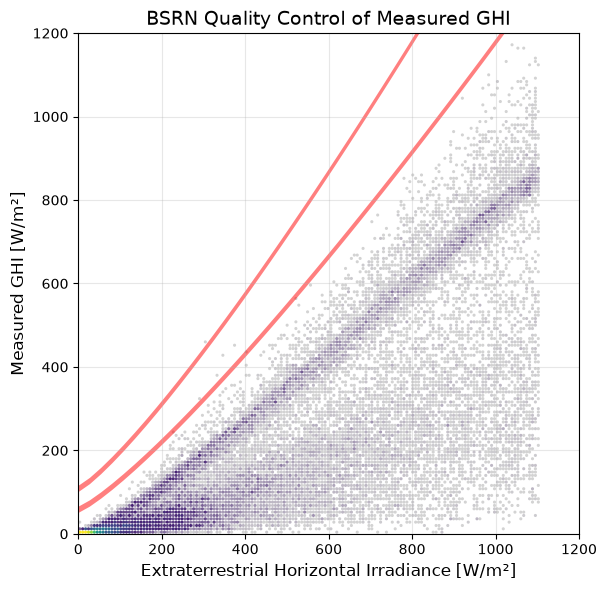

In [346]:
#Plot the data and the BSRN limits
fig, ax = solarpy.plotting.plot_bsrn_limits(
    irradiance=data_raw["ghi"],
    component="ghi",
    ghi_extra=data_raw["ghi_extra"],
)
fig.set_size_inches(12, 6)
ax.set_title("BSRN Quality Control of Measured GHI")
ax.set_xlabel("Extraterrestrial Horizontal Irradiance [W/m²]")
ax.set_ylabel("Measured GHI [W/m²]")
ax.tick_params(axis="both")
ax.grid(alpha=0.3)
ax.set_xlim(0, 1200)
ax.set_ylim(0, 1200)
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

Control check, to see how many options that has been marked:

In [347]:
#Calculate the BSRN upper limits for GHI
_, data_raw["ghi_ppl_upper"] = solarpy.quality.bsrn_limits(
    data_raw["solar_zenith"], data_raw["dni_extra"], limits="ghi-ppl"
)

_, data_raw["ghi_erl_upper"] = solarpy.quality.bsrn_limits(
    data_raw["solar_zenith"], data_raw["dni_extra"], limits="ghi-erl"
)

#Measurements above ERL but within PPL
erl_only = data_raw.loc[
    (data_raw["ghi"] > data_raw["ghi_erl_upper"])
    & (data_raw["ghi"] <= data_raw["ghi_ppl_upper"]),
    ["ghi", "ghi_erl_upper", "ghi_ppl_upper", "solar_zenith"],
]

#Measurements exceeding the physically possible limit (PPL)
above_ppl = data_raw.loc[
    data_raw["ghi"] > data_raw["ghi_ppl_upper"],
    ["ghi", "ghi_ppl_upper", "ghi_erl_upper", "solar_zenith"],
]

#Displaying the number of measurements exceeding the upper limits
print("Number of measurements above the ERL limit but within PPL:", len(erl_only))
print("Number of measurements above the PPL limit:", len(above_ppl))

#Display the total number of violations (upper and lower limits)
print("Total PPL violations:", data_raw["ghi_ppl_flag"].sum())
print("Total ERL violations:", data_raw["ghi_erl_flag"].sum())

display(erl_only)
display(above_ppl)

Number of measurements above the ERL limit but within PPL: 5
Number of measurements above the PPL limit: 1
Total PPL violations: 1
Total ERL violations: 6


parameterId,ghi,ghi_erl_upper,ghi_ppl_upper,solar_zenith
timestamp,,,,
2025-11-16 10:30:00+00:00,383.0,347.653675,472.067093,76.306309
2025-11-16 11:10:00+00:00,427.0,362.386420,490.483025,75.732101
2025-11-19 12:30:00+00:00,327.0,304.900168,418.625210,78.006092
2026-09-16 07:20:00+00:00,438.0,432.730977,578.413721,72.527576
2026-10-10 08:10:00+00:00,453.0,397.368845,534.211056,74.112083


parameterId,ghi,ghi_ppl_upper,ghi_erl_upper,solar_zenith
timestamp,,,,
2025-11-19 10:20:00+00:00,457.0,440.352914,322.282331,77.317319


In [348]:
# Summarize BSRN quality control results
n = data_raw["ghi"].count()

ppl = data_raw["ghi_ppl_flag"].sum()
erl = data_raw["ghi_erl_flag"].sum()

qc_summary = pd.DataFrame({
    "Number of violations": [ppl, erl],
    "Percentage [%]": [ppl / n * 100, erl / n * 100],
}, index=["PPL", "ERL"])

display(qc_summary.round(3))

,Number of violations,Percentage [%]
PPL,1,0.002
ERL,6,0.011


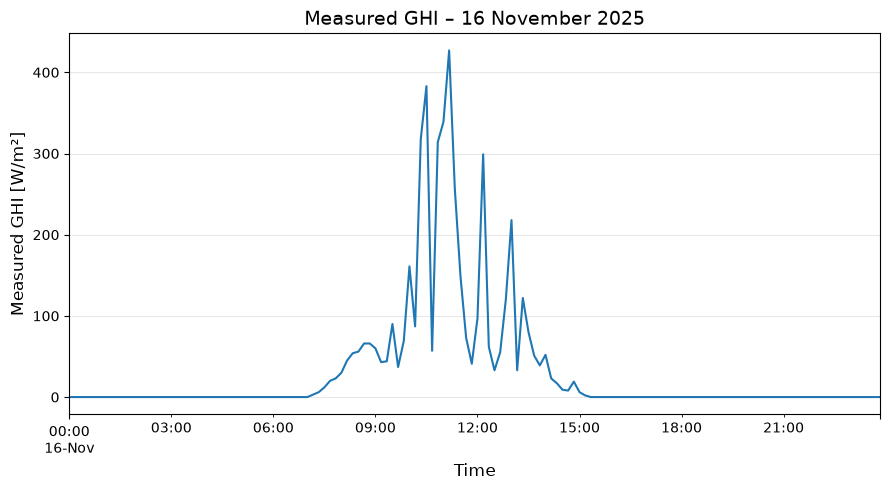

In [349]:
error_data = data_raw.loc["2025-11-16"]

fig, ax = plt.subplots(figsize=(9, 5))

error_data["ghi"].plot(ax=ax)

ax.set_title("Measured GHI – 16 November 2025")
ax.set_xlabel("Time")
ax.set_ylabel("Measured GHI [W/m²]")

ax.tick_params(axis="both")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#display(error_data)

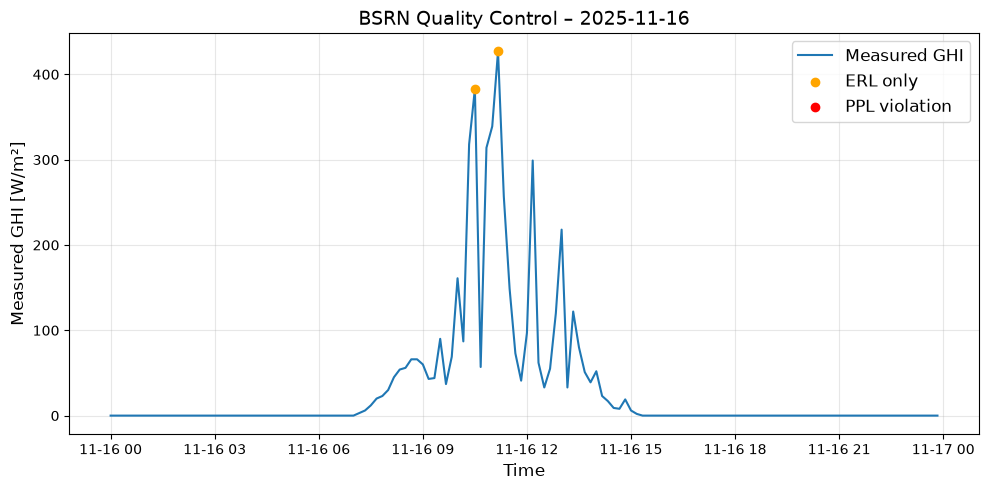

In [350]:
#Select a day with a BSRN violation
flagged_data = data_raw[data_raw["ghi_ppl_flag"] | data_raw["ghi_erl_flag"]]

error_date = flagged_data.index[0].date()
error_data = data_raw.loc[str(error_date)]

#Separate the PPL violations from ERL-only violations
ppl = error_data["ghi_ppl_flag"]
erl_only = error_data["ghi_erl_flag"] & ~ppl

#Plot measured GHI and flagged observations
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(error_data.index, error_data["ghi"], label="Measured GHI")

ax.scatter(
    error_data.index[erl_only],
    error_data.loc[erl_only, "ghi"],
    color="orange",
    label="ERL only",
    zorder=3,
)

ax.scatter(
    error_data.index[ppl],
    error_data.loc[ppl, "ghi"],
    color="red",
    label="PPL violation",
    zorder=3,
)

ax.set_title(f"BSRN Quality Control – {error_date}")
ax.set_xlabel("Time")
ax.set_ylabel("Measured GHI [W/m²]")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Data cleaning and hourly resampling

Measurements violating the BSRN physically possible limits (PPL) are excluded before resampling. The remaining 10-minute GHI measurements are averaged to hourly values for comparison with the NWP forecasts. Hours with fewer than six valid measurements are excluded.

Convert from 10 min resolution to 1 hour with righ closed columns

In [351]:
# Remove measurements violating the physically possible limits
data_clean = data_raw.copy()

data_clean.loc[
    data_clean["ghi_ppl_flag"], "ghi"
] = np.nan

# Resample quality-controlled measurements to hourly values
data_hourly = resample_dmi_ghi_hourly(data_clean)

data_hourly.head(10)

,ghi_measured,n_observations
timestamp,,
2025-11-09 00:00:00+00:00,NaN,1
2025-11-09 01:00:00+00:00,0.000000,6
2025-11-09 02:00:00+00:00,0.000000,6
2025-11-09 03:00:00+00:00,0.000000,6
2025-11-09 04:00:00+00:00,0.000000,6
2025-11-09 05:00:00+00:00,0.000000,6
2025-11-09 06:00:00+00:00,0.000000,6
2025-11-09 07:00:00+00:00,0.500000,6
2025-11-09 08:00:00+00:00,10.500000,6


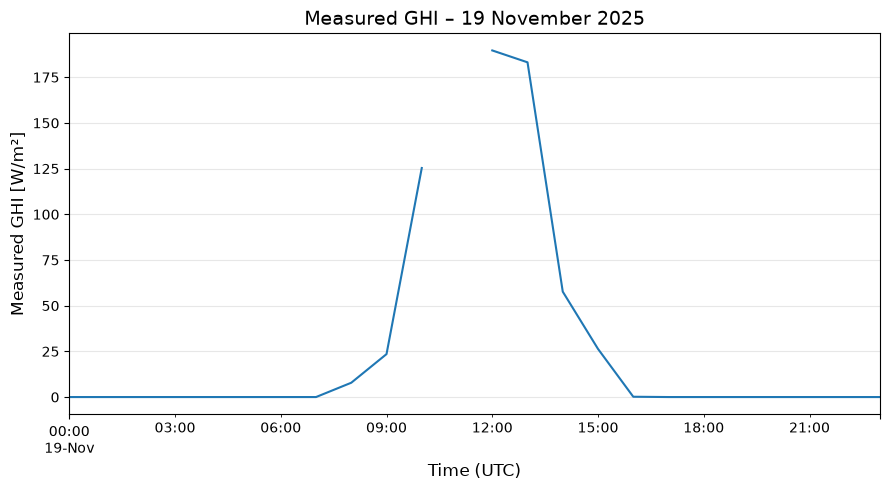

In [352]:
error_data1 = data_hourly.loc["2025-11-19"]

fig, ax = plt.subplots(figsize=(9, 5))

error_data1["ghi_measured"].plot(ax=ax)

ax.set_title("Measured GHI – 19 November 2025", fontsize=14)
ax.set_xlabel("Time (UTC)", fontsize=12)
ax.set_ylabel("Measured GHI [W/m²]", fontsize=12)

ax.tick_params(axis="both", labelsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#display(error_data1)

### Generate plots 

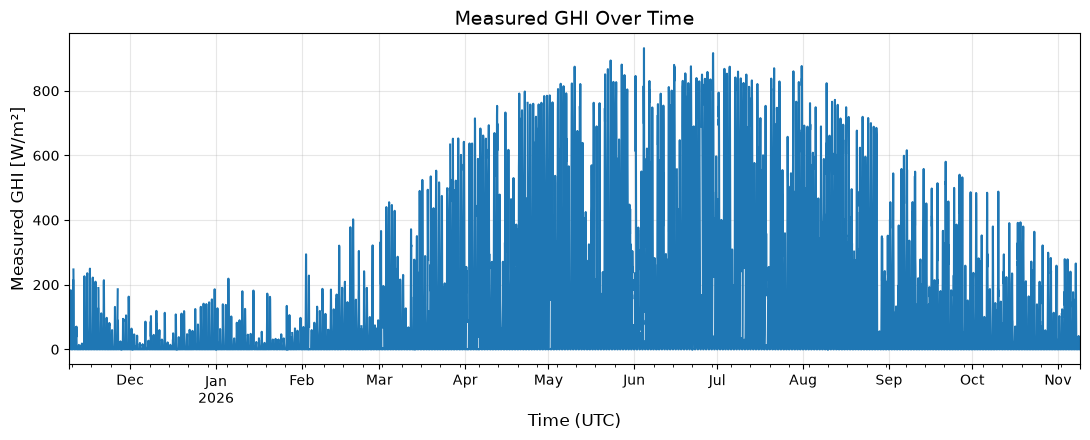

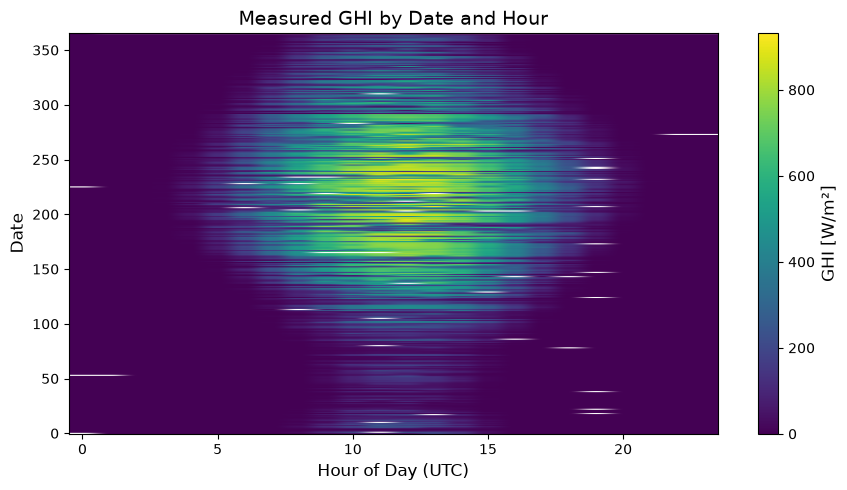

In [353]:
ghi = data_hourly["ghi_measured"].sort_index()

#Time series
fig, ax = plt.subplots(figsize=(11, 4.5))

ghi.plot(ax=ax)

ax.set_title("Measured GHI Over Time")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Measured GHI [W/m²]")

ax.tick_params(axis="both")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


#Heatmap: date vs. hour of day (UTC)
heatmap_data = ghi.to_frame("ghi")
heatmap_data["date"] = heatmap_data.index.date
heatmap_data["hour"] = heatmap_data.index.hour

heatmap = heatmap_data.pivot(index="date",columns="hour",values="ghi")

fig, ax = plt.subplots(figsize=(9, 5))

im = ax.imshow(heatmap, aspect="auto", origin="lower")

ax.set_title("Measured GHI by Date and Hour", fontsize=14)
ax.set_xlabel("Hour of Day (UTC)", fontsize=12)
ax.set_ylabel("Date", fontsize=12)

ax.tick_params(axis="both", labelsize=10)

fig.colorbar(im, ax=ax, label="GHI [W/m²]")

plt.tight_layout()
plt.show()

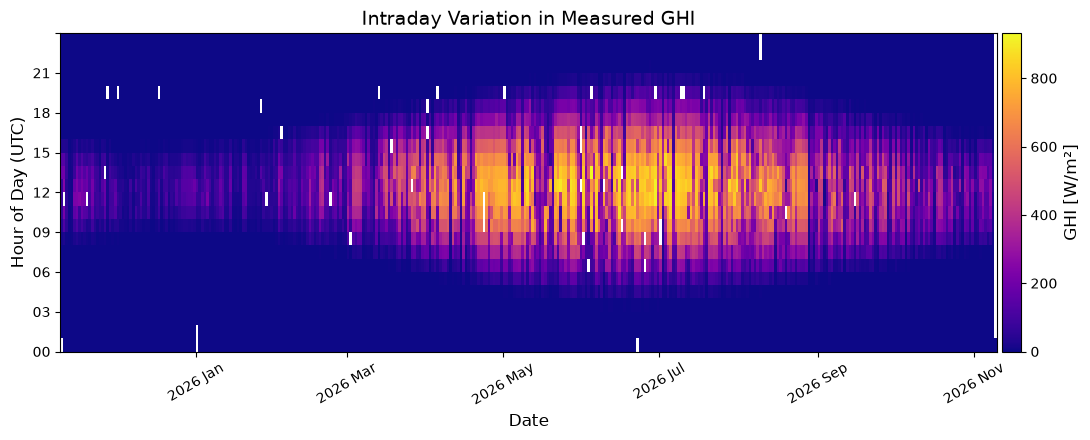

In [354]:
# Intraday heatmap of hourly GHI measurements
fig, ax = solarpy.plotting.plot_intraday_heatmap(
    time=data_hourly.index,
    values=data_hourly["ghi_measured"],
    time_resolution=60,
    cmap="plasma",
    colorbar_label="GHI [W/m²]"
)

fig.set_size_inches(11, 4.5)

ax.set_title("Intraday Variation in Measured GHI")
ax.set_xlabel("Date")
ax.set_ylabel("Hour of Day (UTC)")

plt.tight_layout()
plt.show()

In [355]:
# Use quality-controlled measurements for shading analysis
data = data_clean.copy()

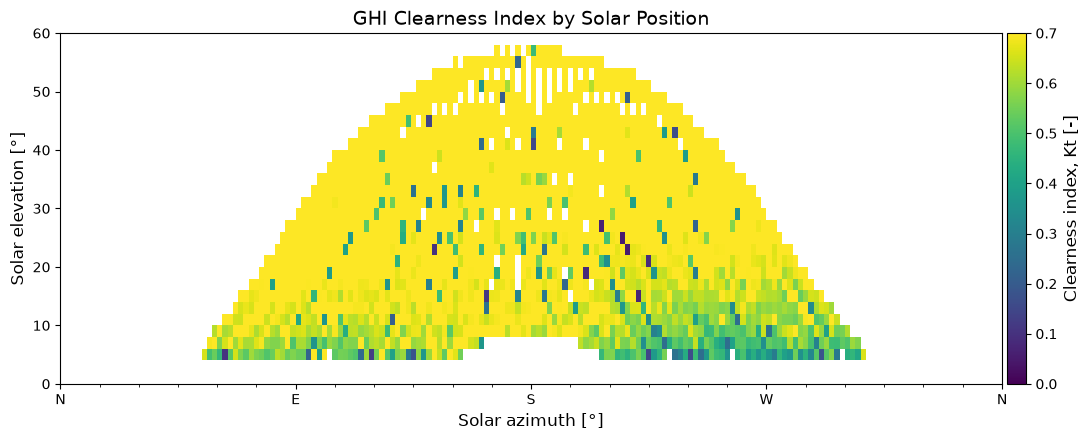

In [356]:
valid = (
    (data["solar_elevation"] > 5)
    & data["ghi"].notna()
    & (data["ghi"] >= 0)
)

fig, ax = plt.subplots(figsize=(11, 4.5))

solarpy.plotting.plot_shading_heatmap(
    value=data.loc[valid, "ghi"] / data.loc[valid, "ghi_extra"],
    solar_azimuth=data.loc[valid, "solar_azimuth"],
    solar_elevation=data.loc[valid, "solar_elevation"],
    azimuth_bin_size=2,
    elevation_bin_size=2,
    encoding="max",
    cmap="viridis",
    norm=Normalize(vmin=0, vmax=0.7),
    colorbar_label="Clearness index, Kt [-]",
    ax=ax,
)

ax.set_title("GHI Clearness Index by Solar Position")
ax.set_xlabel("Solar azimuth [°]")
ax.set_ylabel("Solar elevation [°]")
fig.tight_layout()
plt.show()

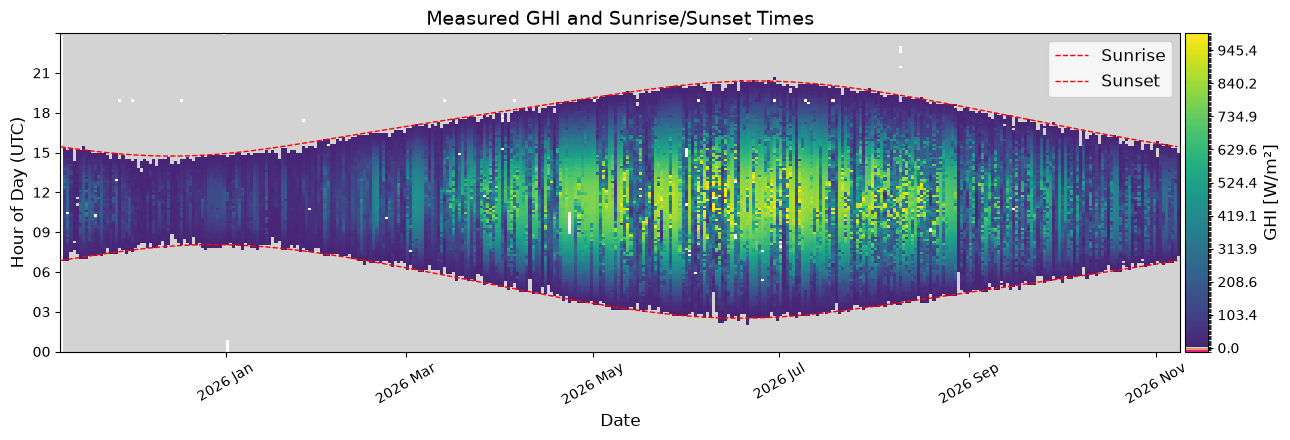

In [357]:
#Plot measured GHI with sunrise and sunset times
cmap, norm = solarpy.plotting.irradiance_colormap_and_norm(vmax=1000)

times = data.index - pd.Timedelta(minutes=5)

fig, ax = plt.subplots(figsize=(13, 4.5))

solarpy.plotting.plot_intraday_heatmap(
    time=times.tz_localize(None),  # Remove timezone information (timestamps remain in UTC)
    values=data["ghi"].to_numpy(),
    time_resolution=10,
    cmap=cmap,
    norm=norm,
    colorbar_label="GHI [W/m²]",
    ax=ax,
)

# Calculate sunrise and sunset for each day
days = pd.date_range(
    times.min().normalize(),
    times.max().normalize(),
    freq="D",
)

sun = pvlib.solarposition.sun_rise_set_transit_spa(
    days,
    latitude=LATITUDE,
    longitude=LONGITUDE,
)

for column, label in [
    ("sunrise", "Sunrise"),
    ("sunset", "Sunset"),
]:
    hour_utc = (
        (sun[column] - sun.index.normalize()).dt.total_seconds() / 3600
    )

    ax.plot(
        days.tz_localize(None),
        hour_utc,
        color="red",
        linestyle="--",
        linewidth=1,
        label=label,
    )

ax.set_title("Measured GHI and Sunrise/Sunset Times")
ax.set_xlabel("Date")
ax.set_ylabel("Hour of Day (UTC)")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

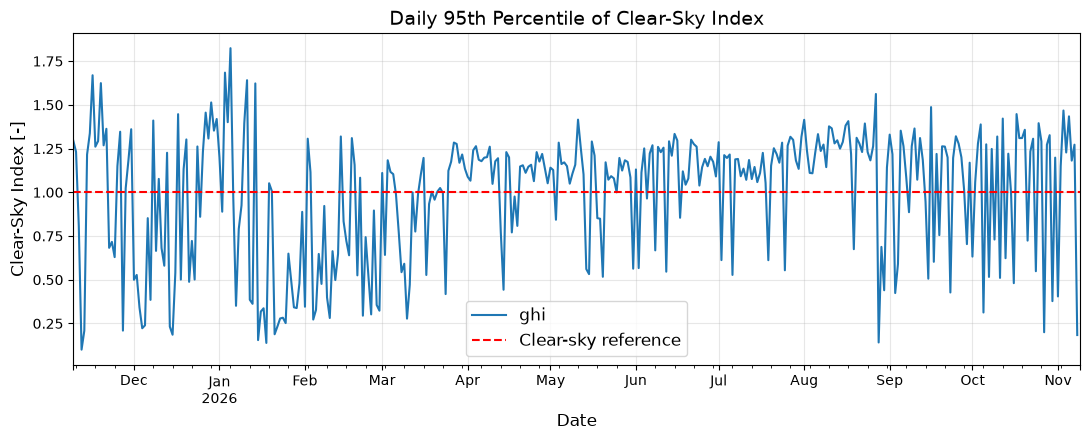

In [358]:
# Calculate clear-sky GHI using pvlib
location = pvlib.location.Location(
    latitude=LATITUDE,
    longitude=LONGITUDE,
    tz="UTC",
)

ghi_clear = location.get_clearsky(
    data_clean.index - pd.Timedelta(minutes=5),
    model="ineichen",
)["ghi"].to_numpy()

# Calculate clear-sky index
kc = data_clean["ghi"] / ghi_clear

kc = kc.where(ghi_clear > 50)

# Plot daily 95th percentile of clear-sky index
fig, ax = plt.subplots(figsize=(11, 4.5))

kc.resample("1D").quantile(0.95).plot(ax=ax)

ax.axhline(1, color="red", linestyle="--", label="Clear-sky reference")
ax.set_title("Daily 95th Percentile of Clear-Sky Index")
ax.set_xlabel("Date")
ax.set_ylabel("Clear-Sky Index [-]")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

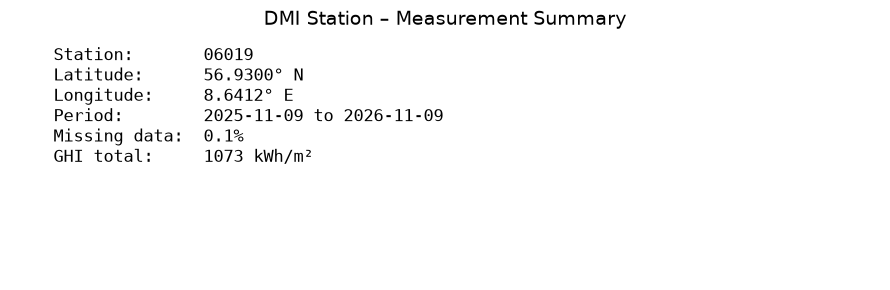

In [360]:
#Summary of measured GHI data
start = data_raw.index.min()
end = data_raw.index.max()

expected = pd.date_range(start, end, freq="10min")
missing = 100 * (1 - data_raw["ghi"].count() / len(expected))

# Integrated GHI from available 10-minute measurements
ghi_total = data_clean["ghi"].clip(lower=0).sum() / 6 / 1000

summary = (
    f"Station:       {STATION}\n"
    f"Latitude:      {LATITUDE:.4f}° N\n"
    f"Longitude:     {LONGITUDE:.4f}° E\n"
    f"Period:        {start:%Y-%m-%d} to {end:%Y-%m-%d}\n"
    f"Missing data:  {missing:.1f}%\n"
    f"GHI total:     {ghi_total:.0f} kWh/m²"
)

fig, ax = plt.subplots(figsize=(9, 3))
ax.axis("off")

ax.text(
    0.05, 0.95, summary,
    transform=ax.transAxes,
    va="top",
    fontsize=12,
    family="monospace",
)

ax.set_title("DMI Station – Measurement Summary")
plt.tight_layout()
plt.show()
